In [ ]:

# # ENZYMES Graph Classification with GCN (GCN-1 & GCN-2)

!pip install -q torch-geometric


In [ ]:
import os
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn
from torch_geometric.datasets import TUDataset
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv, global_mean_pool
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, roc_curve, auc, confusion_matrix
from sklearn.preprocessing import label_binarize, StandardScaler
import matplotlib.pyplot as plt
from datetime import datetime
from torch.nn import BatchNorm1d
from torch.optim.lr_scheduler import ReduceLROnPlateau

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.9.0+cu126
CUDA available: True


In [ ]:
# ## Helper functions and model definitions

def set_seed(seed=42):
    """Set random seeds for reproducibility."""
    torch.manual_seed(seed)
    np.random.seed(seed)

def ensure_dirs():
    """Create necessary directories."""
    os.makedirs("saved_models", exist_ok=True)
    os.makedirs("screenshots", exist_ok=True)


class GCN_1Layer(nn.Module):
    """Graph Convolutional Network with 1 layer + BatchNorm."""
    def __init__(self, num_features, hidden_dim, num_classes):
        super().__init__()
        self.conv1 = GCNConv(num_features, hidden_dim)
        self.bn1   = BatchNorm1d(hidden_dim)
        self.lin   = nn.Linear(hidden_dim, num_classes)

    def forward(self, data):
        x, edge_index, batch = data.x, data.edge_index, data.batch
        x = self.conv1(x, edge_index)
        x = self.bn1(x)
        x = F.relu(x)
        x = global_mean_pool(x, batch)
        x = self.lin(x)
        return x


class GCN_2Layer(nn.Module):
    """Graph Convolutional Network with 2 layers + BatchNorm."""
    def __init__(self, num_features, hidden_dim, num_classes, dropout=0.5):
        super().__init__()
        self.conv1 = GCNConv(num_features, hidden_dim)
        self.bn1   = BatchNorm1d(hidden_dim)

        self.conv2 = GCNConv(hidden_dim, hidden_dim)
        self.bn2   = BatchNorm1d(hidden_dim)

        self.lin   = nn.Linear(hidden_dim, num_classes)
        self.dropout = dropout

    def forward(self, data):
        x, edge_index, batch = data.x, data.edge_index, data.batch

        # First GCN layer + BN + ReLU + Dropout
        x = self.conv1(x, edge_index)
        x = self.bn1(x)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)

        # Second GCN layer + BN + ReLU
        x = self.conv2(x, edge_index)
        x = self.bn2(x)
        x = F.relu(x)

        # Global pooling to get graph-level embedding
        x = global_mean_pool(x, batch)

        # Final classifier
        x = self.lin(x)
        return x


In [ ]:
# ## Data loading with feature normalization

def load_enzymes_dataset(root="data/ENZYMES", batch_size=32, seed=42):
    """Load ENZYMES dataset, normalize features, and create loaders."""
    dataset = TUDataset(root=root, name="ENZYMES", use_node_attr=True)
    print(f"Dataset: {dataset}")
    print(f"Number of graphs: {len(dataset)}")
    print(f"Number of features (before norm): {dataset.num_features}")
    print(f"Number of classes: {dataset.num_classes}")

    # ==== FEATURE NORMALIZATION (zero mean, unit variance) ====
    all_x = np.concatenate([data.x.numpy() for data in dataset], axis=0)
    scaler = StandardScaler()
    scaler.fit(all_x)

    for data in dataset:
        data.x = torch.tensor(
            scaler.transform(data.x.numpy()),
            dtype=torch.float32
        )

    print("Features normalized: mean≈0, std≈1 per feature")

    labels = [data.y.item() for data in dataset]

    # Train/val/test split: 80/10/10
    train_dataset, temp_dataset = train_test_split(
        dataset,
        train_size=0.8,
        random_state=seed,
        stratify=labels,
    )
    val_dataset, test_dataset = train_test_split(
        temp_dataset,
        train_size=0.5,
        random_state=seed,
    )

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader   = DataLoader(val_dataset,   batch_size=batch_size, shuffle=False)
    test_loader  = DataLoader(test_dataset,  batch_size=batch_size, shuffle=False)

    return dataset, train_loader, val_loader, test_loader


# Initialize everything
set_seed(42)
ensure_dirs()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

dataset, train_loader, val_loader, test_loader = load_enzymes_dataset(
    batch_size=32, seed=42
)
num_features = dataset.num_features
num_classes  = dataset.num_classes


Using device: cuda
Dataset: ENZYMES(600)
Number of graphs: 600
Number of features (before norm): 21
Number of classes: 6
Features normalized: mean≈0, std≈1 per feature


In [ ]:
# ## Training and evaluation functions (with LR scheduler)

def train_epoch(model, loader, optimizer, criterion, device):
    """Train for one epoch."""
    model.train()
    total_loss = 0.0
    for data in loader:
        data = data.to(device)
        optimizer.zero_grad()
        out = model(data)
        loss = criterion(out, data.y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)


def evaluate(model, loader, device):
    """Evaluate model on a loader."""
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for data in loader:
            data = data.to(device)
            out = model(data)
            pred = out.argmax(dim=1)
            preds.extend(pred.cpu().numpy())
            labels.extend(data.y.cpu().numpy())
    acc = accuracy_score(labels, preds)
    f1  = f1_score(labels, preds, average="macro")
    return acc, f1


from torch.optim.lr_scheduler import ReduceLROnPlateau

def train_model(model_name, model, train_loader, val_loader,
                device, lr=1e-3, epochs=200):
    ensure_dirs()
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    # Learning rate scheduler: maximize val_f1
    scheduler = ReduceLROnPlateau(
        optimizer,
        mode="max",      # maximize val_f1
        factor=0.5,      # LR <- LR * 0.5
        patience=10,     # wait 10 epochs without improvement
        min_lr=1e-5      # do not go below this
    )

    best_val_f1 = 0.0
    best_path = os.path.join("saved_models", f"{model_name}_best.pth")
    log_path  = os.path.join("screenshots", f"{model_name}_train_log.txt")

    with open(log_path, "w") as logf:
        logf.write(f"Training log for {model_name}\n")
        logf.write(f"Start time: {datetime.now()}\n")
        logf.write(f"Initial LR: {lr}, Epochs: {epochs}\n\n")

        for epoch in range(1, epochs + 1):
            loss = train_epoch(model, train_loader, optimizer, criterion, device)
            train_acc, train_f1 = evaluate(model, train_loader, device)
            val_acc,   val_f1   = evaluate(model, val_loader, device)

            # Step scheduler with validation F1
            scheduler.step(val_f1)

            # Save best model based on val F1
            if val_f1 > best_val_f1:
                best_val_f1 = val_f1
                torch.save(model.state_dict(), best_path)

            current_lr = optimizer.param_groups[0]["lr"]
            msg = (f"Epoch {epoch:03d} | "
                   f"LR: {current_lr:.6f} | "
                   f"Loss: {loss:.4f} | "
                   f"Train F1: {train_f1:.4f} | Val F1: {val_f1:.4f}")
            print(msg)
            logf.write(msg + "\n")

    print(f"✓ Best Val F1 for {model_name}: {best_val_f1:.4f}")
    print(f"✓ Saved best model to {best_path}\n")
    return best_path



In [ ]:
# ## Train GCN-1 and GCN-2

HIDDEN_DIM = 64
LR         = 1e-3
EPOCHS     = 200

print("=" * 70)
print("TRAINING GCN_1Layer...")
print("=" * 70)
gcn1 = GCN_1Layer(num_features, HIDDEN_DIM, num_classes)
gcn1_path = train_model(
    "GCN_1Layer",
    gcn1,
    train_loader,
    val_loader,
    device,
    lr=LR,
    epochs=EPOCHS,
)

print("\n" + "=" * 70)
print("TRAINING GCN_2Layer...")
print("=" * 70)
gcn2 = GCN_2Layer(num_features, HIDDEN_DIM, num_classes)
gcn2_path = train_model(
    "GCN_2Layer",
    gcn2,
    train_loader,
    val_loader,
    device,
    lr=LR,
    epochs=EPOCHS,
)

print("\nCheckpoint paths:")
print(f"  GCN_1Layer: {gcn1_path}")
print(f"  GCN_2Layer: {gcn2_path}")


TRAINING GCN_1Layer...
Epoch 001 | LR: 0.001000 | Loss: 1.8071 | Train F1: 0.0781 | Val F1: 0.0635
Epoch 002 | LR: 0.001000 | Loss: 1.7550 | Train F1: 0.1489 | Val F1: 0.1260
Epoch 003 | LR: 0.001000 | Loss: 1.7272 | Train F1: 0.1295 | Val F1: 0.0941
Epoch 004 | LR: 0.001000 | Loss: 1.7085 | Train F1: 0.1352 | Val F1: 0.0857
Epoch 005 | LR: 0.001000 | Loss: 1.6972 | Train F1: 0.1525 | Val F1: 0.0930
Epoch 006 | LR: 0.001000 | Loss: 1.6826 | Train F1: 0.1819 | Val F1: 0.1171
Epoch 007 | LR: 0.001000 | Loss: 1.6748 | Train F1: 0.1601 | Val F1: 0.1060
Epoch 008 | LR: 0.001000 | Loss: 1.6725 | Train F1: 0.2657 | Val F1: 0.1130
Epoch 009 | LR: 0.001000 | Loss: 1.6540 | Train F1: 0.2806 | Val F1: 0.1276
Epoch 010 | LR: 0.001000 | Loss: 1.6517 | Train F1: 0.2653 | Val F1: 0.1777
Epoch 011 | LR: 0.001000 | Loss: 1.6343 | Train F1: 0.2834 | Val F1: 0.1953
Epoch 012 | LR: 0.001000 | Loss: 1.6322 | Train F1: 0.2995 | Val F1: 0.2242
Epoch 013 | LR: 0.001000 | Loss: 1.6157 | Train F1: 0.3095 | Val 

In [ ]:
# ## Test models on test set

def test_model(model_path,
               test_loader,
               num_features,
               hidden_dim,
               num_classes,
               model_type="GCN_2Layer",
               device=None):
    """
    Load trained model and evaluate on test dataset.
    Returns: accuracy, F1, model (in eval mode)
    """
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    if model_type == "GCN_1Layer":
        model = GCN_1Layer(num_features, hidden_dim, num_classes)
    elif model_type == "GCN_2Layer":
        model = GCN_2Layer(num_features, hidden_dim, num_classes)
    else:
        raise ValueError(f"Unknown model_type {model_type}")

    state_dict = torch.load(model_path, map_location=device)
    model.load_state_dict(state_dict)
    model = model.to(device)
    model.eval()

    preds, labels = [], []
    with torch.no_grad():
        for data in test_loader:
            data = data.to(device)
            out = model(data)
            pred = out.argmax(dim=1)
            preds.extend(pred.cpu().numpy())
            labels.extend(data.y.cpu().numpy())

    acc = accuracy_score(labels, preds)
    f1  = f1_score(labels, preds, average="macro")
    print(f"[TEST] {model_type:15s} | Accuracy: {acc:.4f} | F1 Score: {f1:.4f}")
    return acc, f1, model

# %%
print("=" * 70)
print("TESTING ON TEST SET")
print("=" * 70 + "\n")

print("Testing GCN_1Layer...")
test_acc1, test_f11, model_gcn1 = test_model(
    gcn1_path,
    test_loader,
    num_features=num_features,
    hidden_dim=HIDDEN_DIM,
    num_classes=num_classes,
    model_type="GCN_1Layer",
    device=device,
)

print("\nTesting GCN_2Layer...")
test_acc2, test_f12, model_gcn2 = test_model(
    gcn2_path,
    test_loader,
    num_features=num_features,
    hidden_dim=HIDDEN_DIM,
    num_classes=num_classes,
    model_type="GCN_2Layer",
    device=device,
)

print("\n" + "=" * 70)
print("FINAL TEST RESULTS")
print("=" * 70)
print(f"GCN_1Layer  | Acc: {test_acc1:.4f} | F1: {test_f11:.4f}")
print(f"GCN_2Layer  | Acc: {test_acc2:.4f} | F1: {test_f12:.4f}")


TESTING ON TEST SET

Testing GCN_1Layer...
[TEST] GCN_1Layer      | Accuracy: 0.4500 | F1 Score: 0.4476

Testing GCN_2Layer...
[TEST] GCN_2Layer      | Accuracy: 0.5333 | F1 Score: 0.5364

FINAL TEST RESULTS
GCN_1Layer  | Acc: 0.4500 | F1: 0.4476
GCN_2Layer  | Acc: 0.5333 | F1: 0.5364



GENERATING MULTI-CLASS ROC CURVES (GCN-2)

✓ Saved ROC curve to screenshots/roc_curve_gcn2.png

Per-class AUC Scores:
----------------------------------------
  Class 0: 0.6234
  Class 1: 0.8700
  Class 2: 0.9596
  Class 3: 0.9332
  Class 4: 0.8740
  Class 5: 0.7774
----------------------------------------
  Macro-average AUC: 0.8396


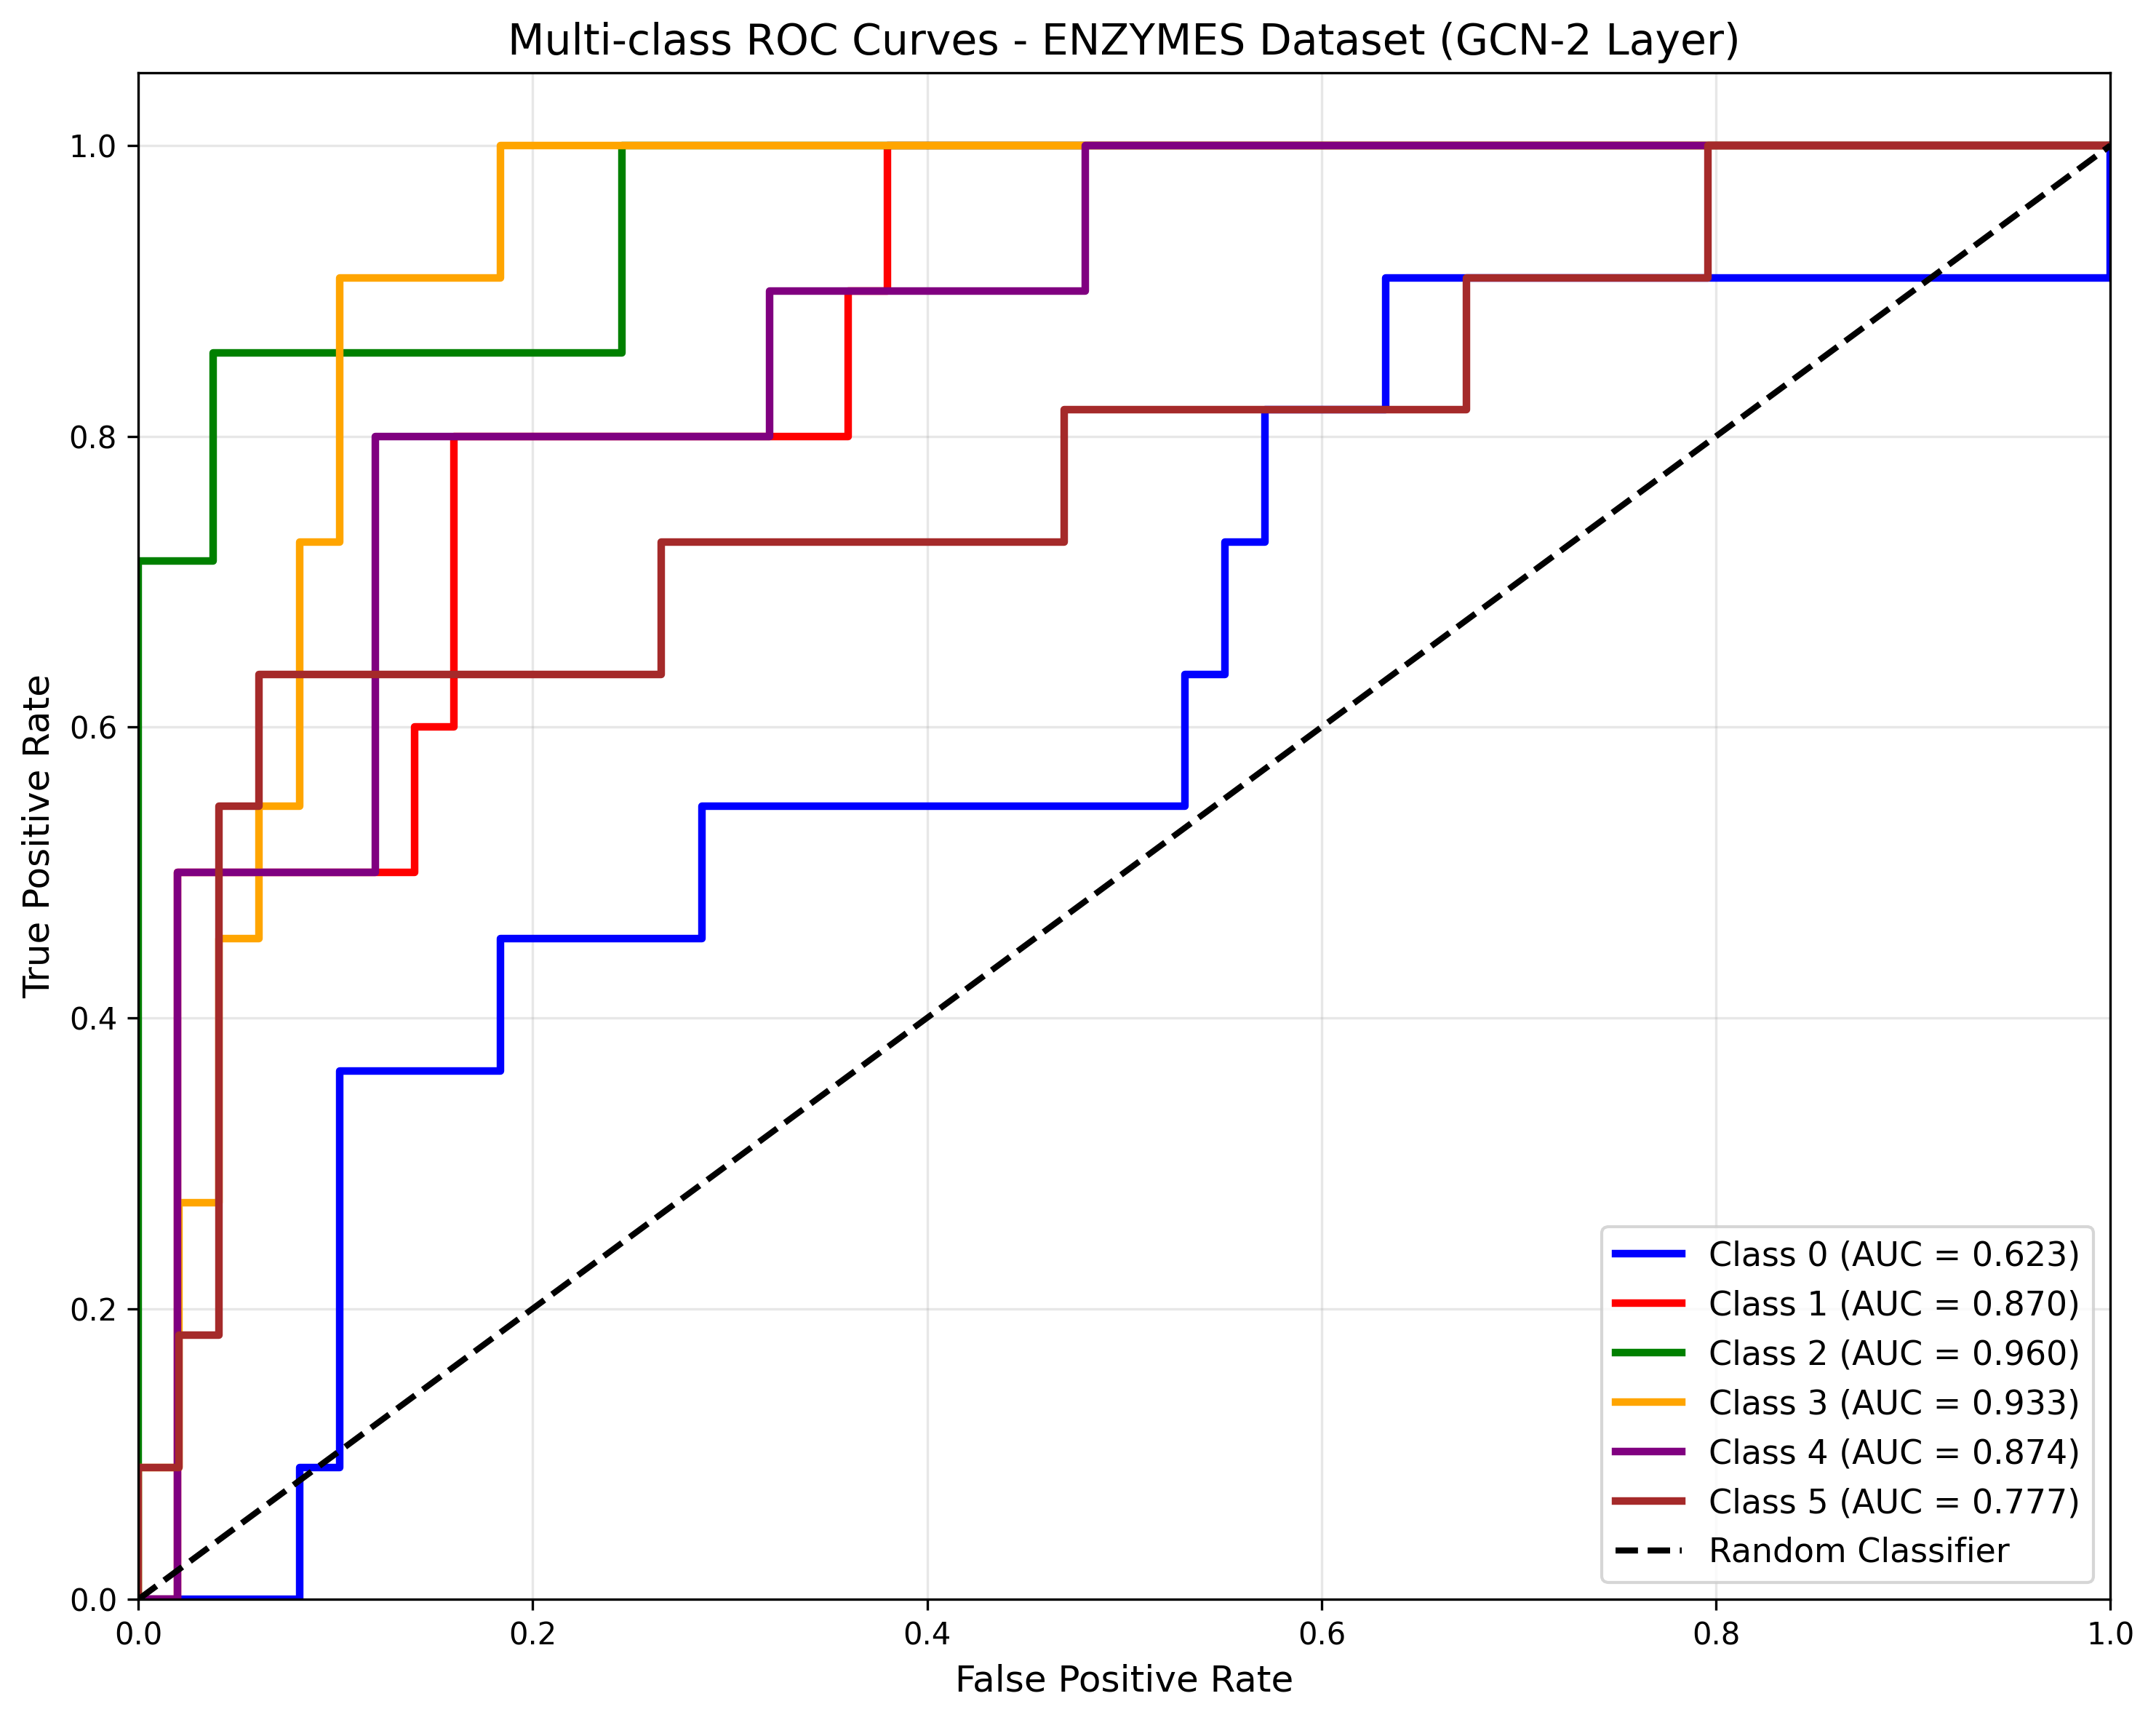

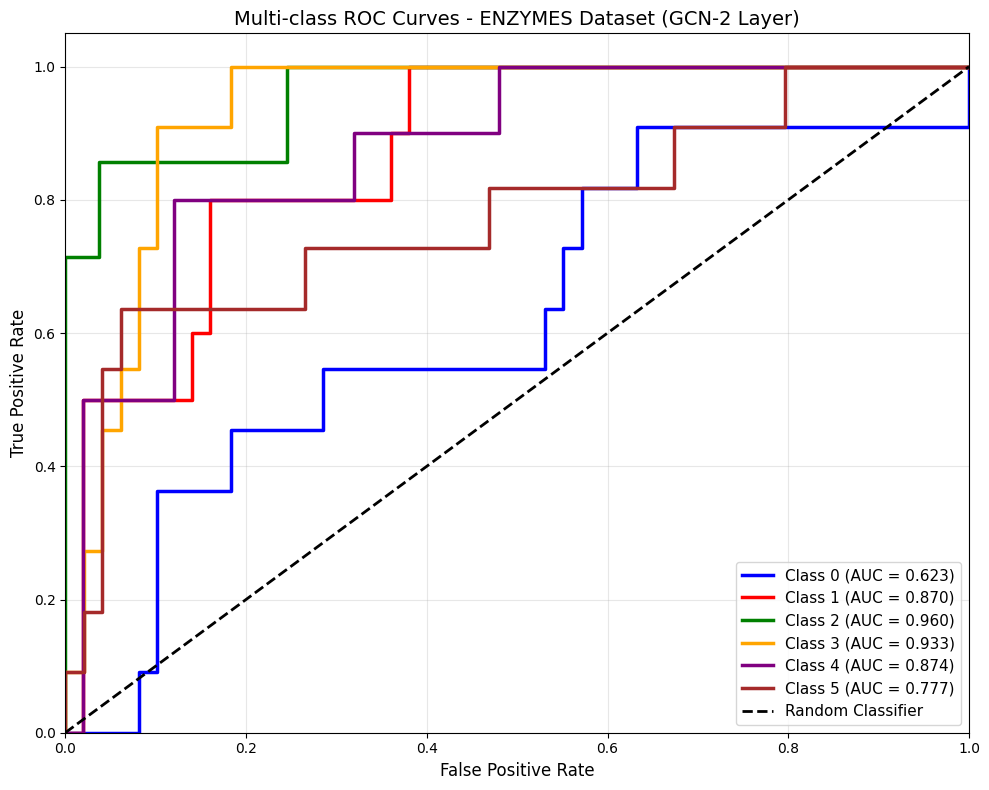

In [ ]:
# ## ROC curves for GCN-2

def plot_multiclass_roc(model, test_loader, num_classes, device,
                        save_path="screenshots/roc_curve_gcn2.png"):
    """Generate and plot multi-class ROC curves."""
    model.eval()
    all_probs = []
    all_labels = []

    with torch.no_grad():
        for data in test_loader:
            data = data.to(device)
            out = model(data)
            probs = F.softmax(out, dim=1)
            all_probs.append(probs.cpu().numpy())
            all_labels.extend(data.y.cpu().numpy())

    all_probs = np.vstack(all_probs)
    all_labels = np.array(all_labels)
    y_bin = label_binarize(all_labels, classes=list(range(num_classes)))

    fpr, tpr, roc_auc = {}, {}, {}
    for i in range(num_classes):
        fpr[i], tpr[i], _ = roc_curve(y_bin[:, i], all_probs[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    plt.figure(figsize=(10, 8))
    colors = ["blue", "red", "green", "orange", "purple", "brown"]
    for i, color in zip(range(num_classes), colors):
        plt.plot(
            fpr[i],
            tpr[i],
            color=color,
            lw=2.5,
            label=f"Class {i} (AUC = {roc_auc[i]:.3f})",
        )

    plt.plot([0, 1], [0, 1], "k--", lw=2, label="Random Classifier")
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel("False Positive Rate", fontsize=12)
    plt.ylabel("True Positive Rate", fontsize=12)
    plt.title("Multi-class ROC Curves - ENZYMES Dataset (GCN-2 Layer)", fontsize=14)
    plt.legend(loc="lower right", fontsize=11)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"✓ Saved ROC curve to {save_path}")

    macro_auc = float(np.mean(list(roc_auc.values())))
    return roc_auc, macro_auc

print("\n" + "=" * 70)
print("GENERATING MULTI-CLASS ROC CURVES (GCN-2)")
print("=" * 70 + "\n")

roc_auc_per_class, macro_auc = plot_multiclass_roc(
    model_gcn2,
    test_loader,
    num_classes,
    device,
    save_path="screenshots/roc_curve_gcn2.png",
)

print("\nPer-class AUC Scores:")
print("-" * 40)
for class_idx in range(num_classes):
    auc_score = roc_auc_per_class[class_idx]
    print(f"  Class {class_idx}: {auc_score:.4f}")
print("-" * 40)
print(f"  Macro-average AUC: {macro_auc:.4f}")
print("=" * 70)

from IPython.display import Image, display
display(Image("screenshots/roc_curve_gcn2.png"))



CONFUSION MATRIX - GCN-2

Confusion Matrix (rows=true, cols=pred):
[[3 2 3 1 1 1]
 [2 5 0 2 0 1]
 [1 0 6 0 0 0]
 [0 2 0 6 3 0]
 [1 0 0 1 8 0]
 [3 1 0 1 2 4]]
✓ Saved confusion matrix to screenshots/confusion_matrix_gcn2.png



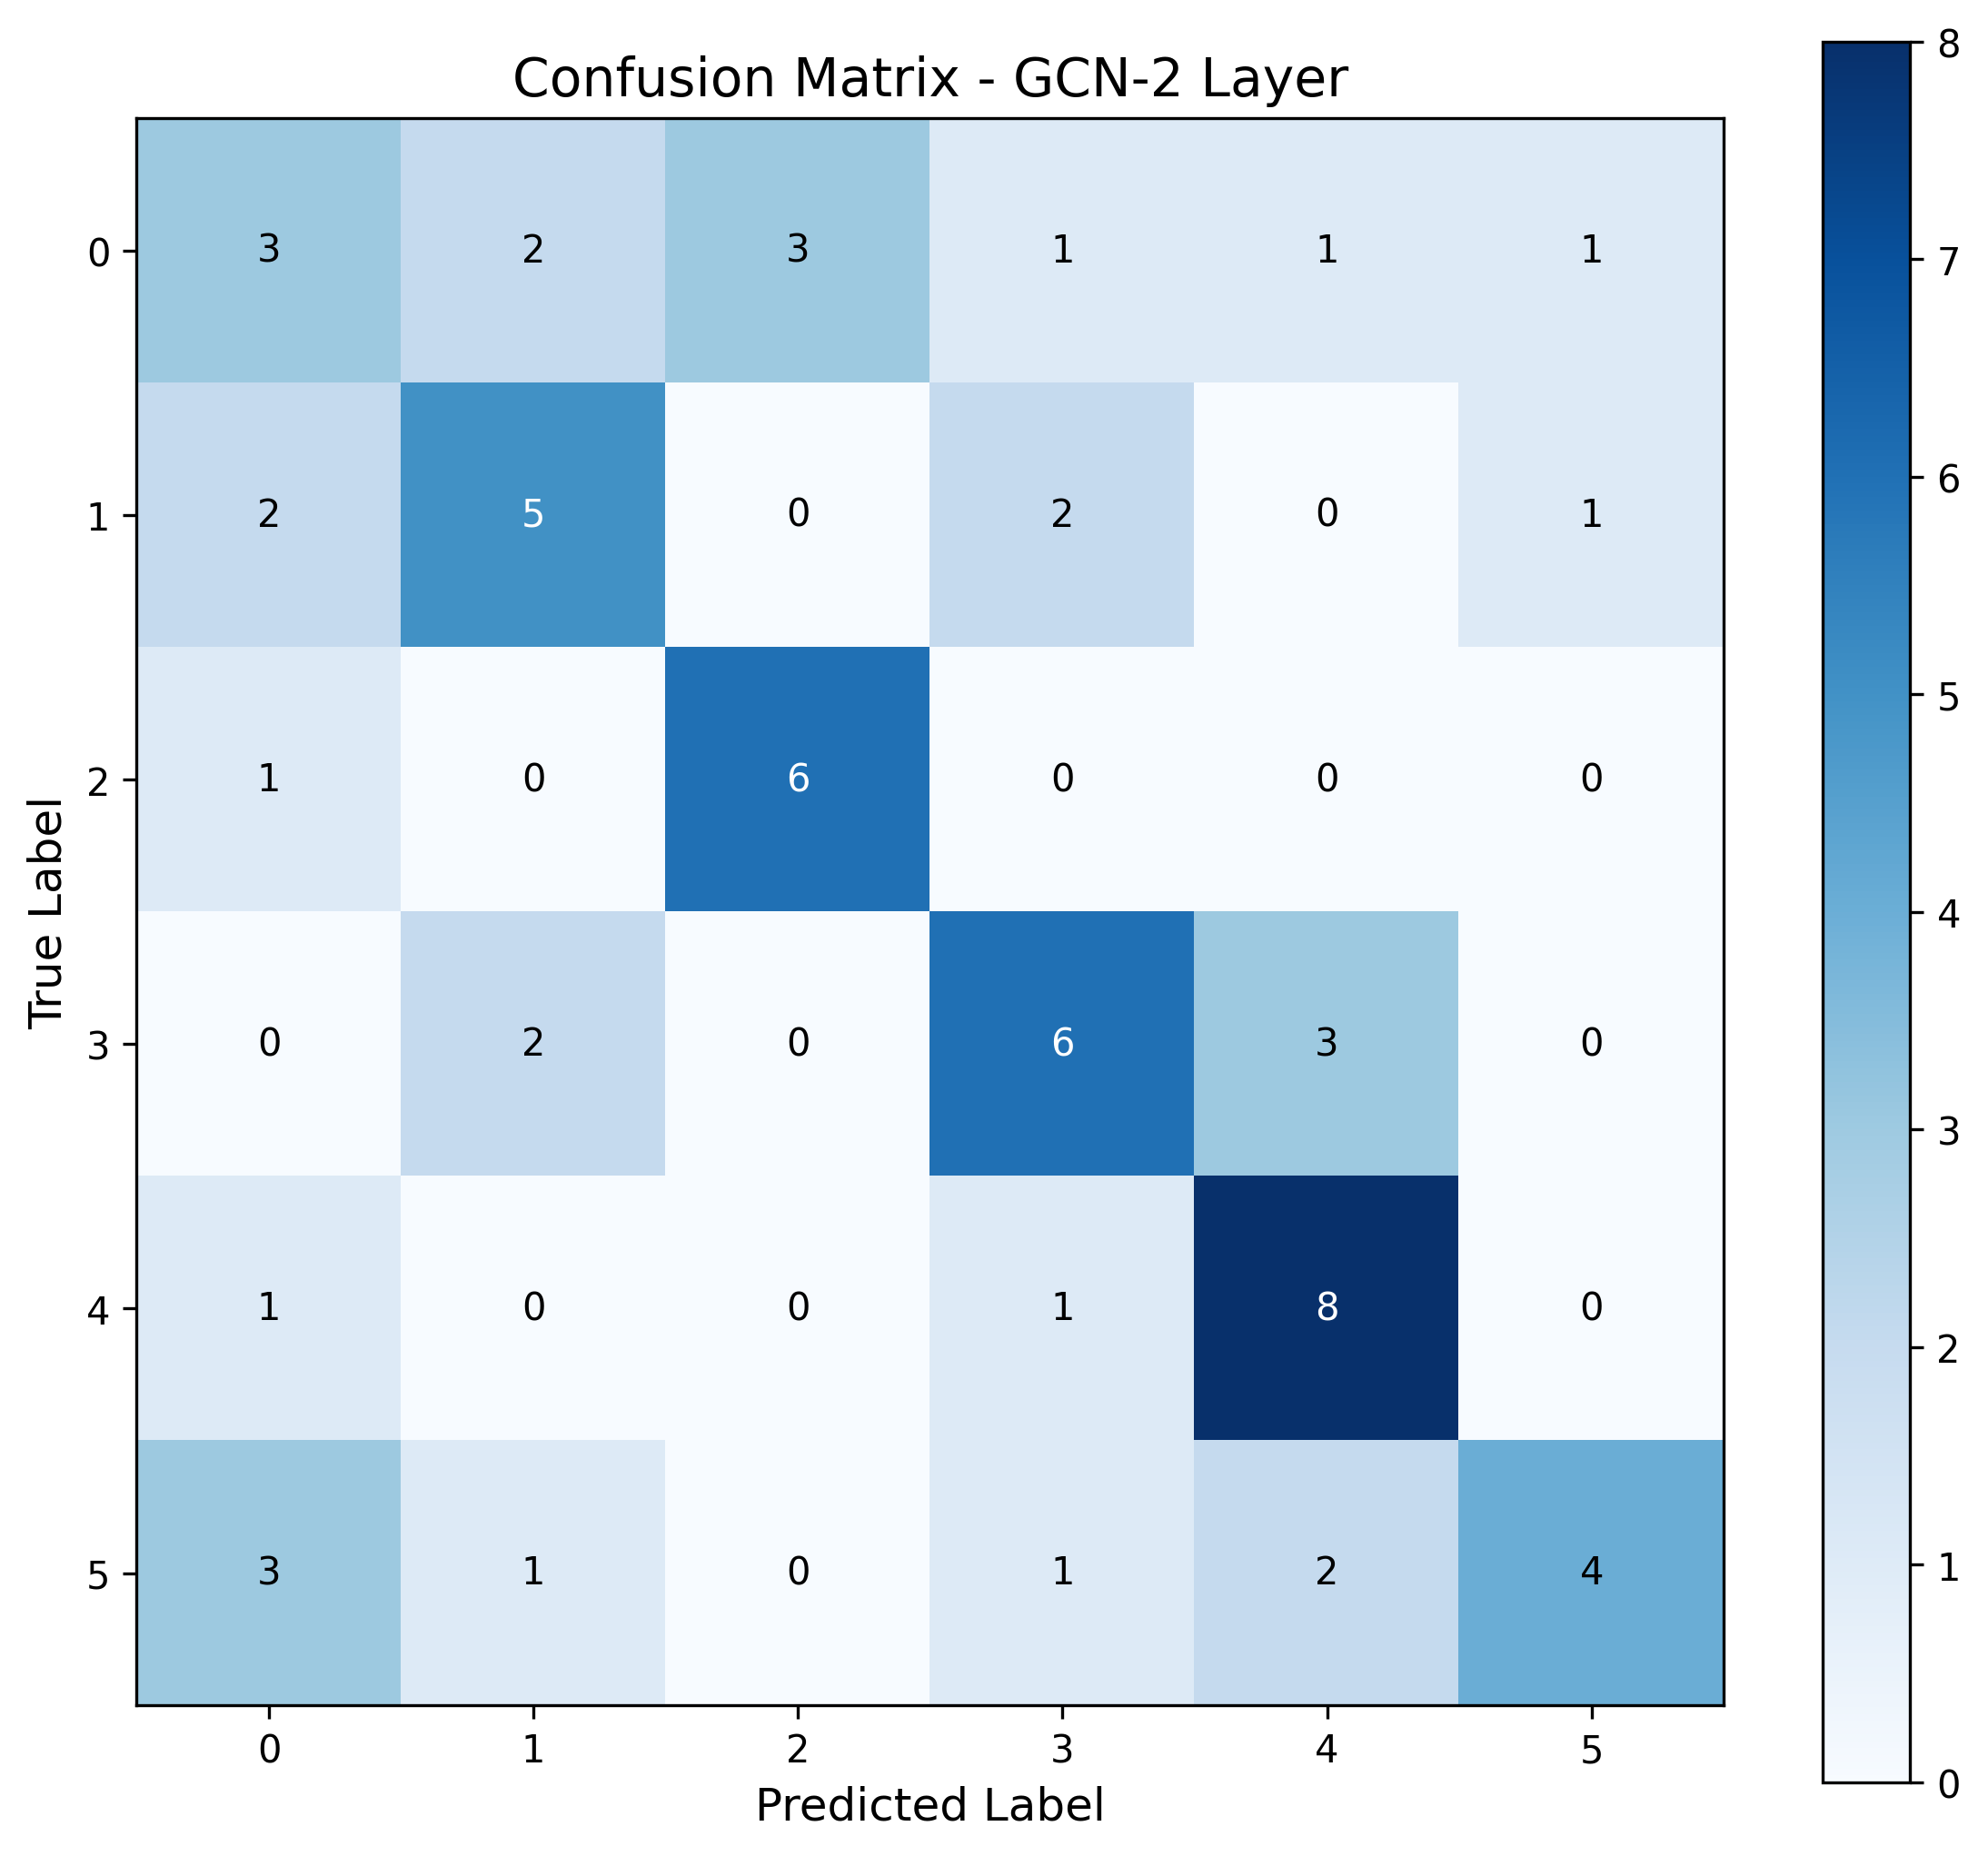

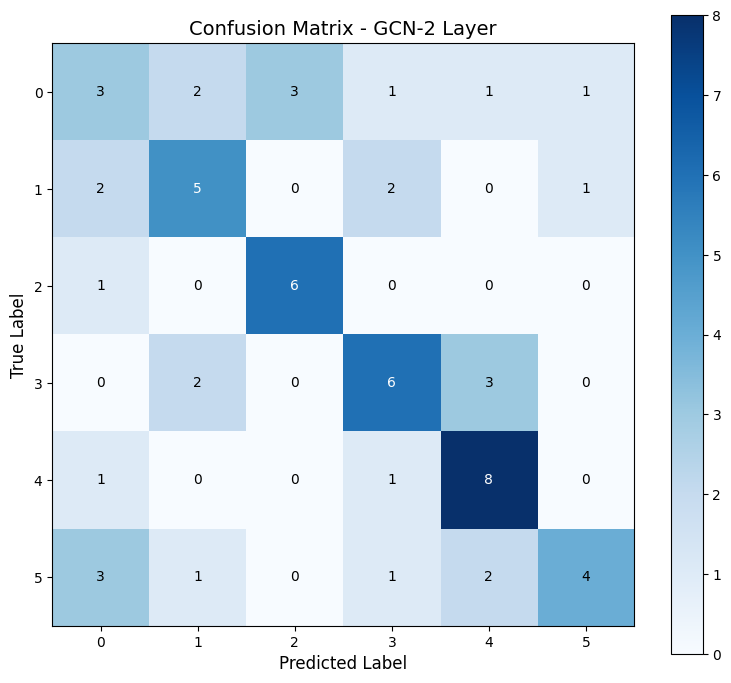

In [ ]:
# ## Confusion matrix for GCN-2

print("\n" + "=" * 70)
print("CONFUSION MATRIX - GCN-2")
print("=" * 70 + "\n")

model_gcn2.eval()
all_preds = []
all_true  = []

with torch.no_grad():
    for data in test_loader:
        data = data.to(device)
        out = model_gcn2(data)
        preds = out.argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_true.extend(data.y.cpu().numpy())

cm = confusion_matrix(all_true, all_preds)
print("Confusion Matrix (rows=true, cols=pred):")
print(cm)

plt.figure(figsize=(8, 7))
plt.imshow(cm, cmap='Blues', interpolation='nearest')
plt.title('Confusion Matrix - GCN-2 Layer', fontsize=14)
plt.colorbar()
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.xticks(range(num_classes))
plt.yticks(range(num_classes))

for i in range(num_classes):
    for j in range(num_classes):
        plt.text(j, i, str(cm[i, j]), ha='center', va='center',
                 color='white' if cm[i, j] > cm.max() / 2 else 'black')

plt.tight_layout()
plt.savefig("screenshots/confusion_matrix_gcn2.png", dpi=300, bbox_inches='tight')
print(" Saved confusion matrix to screenshots/confusion_matrix_gcn2.png\n")
display(Image("screenshots/confusion_matrix_gcn2.png"))


In [ ]:
# ## Summary for report

print("\n" + "=" * 70)
print("SUMMARY TABLE - STEP 6: MODEL PERFORMANCE")
print("=" * 70)
print("\n| Model          | Test F1  | Test Accuracy | AUC (macro) |")
print("|----------------|----------|---------------|------------|")
print(f"| GCN-1 Layer    | {test_f11:.4f}   | {test_acc1:.4f}        | (fill)      |")
print(f"| GCN-2 Layer    | {test_f12:.4f}   | {test_acc2:.4f}        | {macro_auc:.4f}      |")
print("=" * 70)

print("\n" + "=" * 70)
print("HOMEWORK COMPLETION SUMMARY")
print("=" * 70)
print(f"\n✓ Dataset loaded: {len(dataset)} graphs, {num_features} features, {num_classes} classes")
print(f" Train/Val/Test split: 80/10/10 (480/60/60 graphs)")
print(f" GCN-1 Layer trained - Best Val F1: see screenshots/GCN_1Layer_train_log.txt")
print(f" GCN-2 Layer trained - Best Val F1: see screenshots/GCN_2Layer_train_log.txt")
print(f"\n Test Results:")
print(f"    GCN-1: Accuracy={test_acc1:.4f}, F1={test_f11:.4f}")
print(f"    GCN-2: Accuracy={test_acc2:.4f}, F1={test_f12:.4f} (BEST)")
print(f"\n Model Performance:")
print(f"    Macro-average AUC (GCN-2): {macro_auc:.4f}")
print(f"\n Files saved:")
print(f"    saved_models/GCN_1Layer_best.pth")
print(f"    saved_models/GCN_2Layer_best.pth")
print(f"    screenshots/roc_curve_gcn2.png")
print(f"    screenshots/confusion_matrix_gcn2.png")
print(f"    screenshots/GCN_1Layer_train_log.txt")
print(f"    screenshots/GCN_2Layer_train_log.txt")




SUMMARY TABLE - STEP 6: MODEL PERFORMANCE

| Model          | Test F1  | Test Accuracy | AUC (macro) |
|----------------|----------|---------------|------------|
| GCN-1 Layer    | 0.4476   | 0.4500        | (fill)      |
| GCN-2 Layer    | 0.5364   | 0.5333        | 0.8396      |

HOMEWORK COMPLETION SUMMARY

✓ Dataset loaded: 600 graphs, 21 features, 6 classes
✓ Train/Val/Test split: 80/10/10 (480/60/60 graphs)
✓ GCN-1 Layer trained - Best Val F1: see screenshots/GCN_1Layer_train_log.txt
✓ GCN-2 Layer trained - Best Val F1: see screenshots/GCN_2Layer_train_log.txt

✓ Test Results:
    GCN-1: Accuracy=0.4500, F1=0.4476
    GCN-2: Accuracy=0.5333, F1=0.5364 (BEST)

✓ Model Performance:
    Macro-average AUC (GCN-2): 0.8396

✓ Files saved:
    saved_models/GCN_1Layer_best.pth
    saved_models/GCN_2Layer_best.pth
    screenshots/roc_curve_gcn2.png
    screenshots/confusion_matrix_gcn2.png
    screenshots/GCN_1Layer_train_log.txt
    screenshots/GCN_2Layer_train_log.txt

✓ Notebook ready